# NYC Food Safety Inspection Model
*Predicting serious health-inspection failures in NYC restaurants*

## Part 2: Baseline Model

This notebook builds the **baseline model** that later models (Module 24) must beat. It uses the modeling table created in [Part 1](01_data_cleaning_and_eda.ipynb): one row per routine inspection, with features built only from each restaurant's earlier inspections.

**Steps:**
1. Choose an evaluation metric that fits the problem.
2. Split the data by time: train on the past, test on the future.
3. Set reference points: a "do-nothing" model and a simple rule of thumb.
4. Train a **logistic regression** baseline and evaluate it.
5. Interpret the results in plain language.

## 1. Setup

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (ConfusionMatrixDisplay, accuracy_score, average_precision_score,
                             classification_report, precision_recall_curve, roc_auc_score)
from sklearn.model_selection import TimeSeriesSplit, cross_val_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

sns.set_theme(style="whitegrid", context="notebook", palette="deep")
plt.rcParams.update({"figure.dpi": 110, "axes.titleweight": "bold", "axes.titlesize": 13})
pd.set_option("display.float_format", "{:,.3f}".format)

PROCESSED_PATH = Path("../data/processed/model_table.csv.gz")
IMAGES_DIR = Path("../images")
RANDOM_STATE = 42
FAIL_COLOR, PASS_COLOR, GRAY = "#c0392b", "#2e86c1", "#7f8c8d"


def save_fig(fig, name):
    """Save a figure to images/ so the README can show it."""
    fig.savefig(IMAGES_DIR / f"{name}.png", bbox_inches="tight", dpi=130)

## 2. Load the modeling table

In [2]:
model_df = pd.read_csv(PROCESSED_PATH, parse_dates=["inspection_date"]).sort_values("inspection_date")
print(f"{len(model_df):,} routine inspections from {model_df['inspection_date'].min():%d %b %Y} "
      f"to {model_df['inspection_date'].max():%d %b %Y}; serious failure rate {model_df['fail'].mean():.1%}")

46,000 routine inspections from 06 Jan 2022 to 21 Oct 2026; serious failure rate 18.1%


**Features used.** The inspection's own score, ID and date are excluded, because the score *is* the answer and the ID would let the model memorize restaurants. `prior_harborage_visits` is dropped because it duplicates `prior_pest_visits` (r = 0.97, see Part 1).

In [3]:
NUMERIC_FEATURES = ["prev_cycle_score", "prev_cycle_fail", "days_since_prev_cycle", "last_score", "prior_mean_score",
                    "last_n_critical", "last_had_pest", "prior_pest_visits", "prior_temperature_visits",
                    "prior_hygiene_visits", "prior_no_fpc_visits", "prior_closed_visits", "n_prior_inspections",
                    "days_since_last_inspection", "has_prior_inspection", "chain_size", "is_chain"]
CATEGORICAL_FEATURES = ["boro", "cuisine_group", "inspection_month", "inspection_dow"]
TARGET = "fail"

X = model_df[NUMERIC_FEATURES + CATEGORICAL_FEATURES]
y = model_df[TARGET]
print(f"{len(NUMERIC_FEATURES)} numeric + {len(CATEGORICAL_FEATURES)} categorical features")

17 numeric + 4 categorical features


## 3. Choosing the evaluation metric

**Why not accuracy?** Only about 18% of routine inspections are serious failures. A model that always says "pass" would be 82% accurate and catch **zero** failures. Accuracy hides exactly the cases we care about.

**What matters to the Health Department?** Inspectors will use the model as a **ranked "visit these first" list**. The two questions are:
* Of the restaurants we flag, how many really fail? (**precision**, i.e., inspector time well spent)
* Of all the restaurants that fail, how many did we flag? (**recall**, i.e., unsafe kitchens caught)

Missing a failing restaurant (a false negative) is worse than an extra visit to a clean one (a false positive), but inspector time is limited, so both matter.

**Primary metric: PR-AUC (average precision).** It summarizes precision across every possible recall level, i.e., across every length of the "visit first" list. It is the standard choice when the positive class is rare. A useless model scores about the failure rate (≈ 0.18); a perfect model scores 1.0.

**Plain-language companion: capture rate.** If inspectors visit the riskiest 20% of restaurants first, what share of all serious failures do they find? A random order would find 20%.

ROC-AUC is reported too, because published inspection-targeting studies use it, but it can look optimistic on imbalanced data.

## 4. Train/test split by time

A random split would let the model learn from inspections that happen *after* the ones it is tested on, which is impossible in real use. Instead, the **earliest 80%** of inspections (by date) are used for training and the **most recent 20%** for testing. This mimics the real situation: train on everything up to today, predict upcoming inspections.

In [4]:
cutoff_date = model_df["inspection_date"].quantile(0.8)
is_train = model_df["inspection_date"] < cutoff_date
X_train, X_test = X[is_train], X[~is_train]
y_train, y_test = y[is_train], y[~is_train]

split_summary = pd.DataFrame({
    "period": [f"{model_df.loc[is_train, 'inspection_date'].min():%b %Y} – {model_df.loc[is_train, 'inspection_date'].max():%b %Y}",
               f"{model_df.loc[~is_train, 'inspection_date'].min():%b %Y} – {model_df.loc[~is_train, 'inspection_date'].max():%b %Y}"],
    "inspections": [len(y_train), len(y_test)],
    "failure_rate": [y_train.mean(), y_test.mean()]}, index=["train", "test"])
split_summary

,period,inspections,failure_rate
train,Jan 2022 – Apr 2026,36774,0.173
test,Apr 2026 – Oct 2026,9226,0.213


## 5. Preprocessing pipeline

All preprocessing lives inside a scikit-learn `Pipeline`, so it is learned from the training data only and applied identically to new data:
* **Numeric features:** fill missing values with the training median and add a "was missing" flag (missing history means a new restaurant, which is informative), then standardize.
* **Categorical features:** fill missing with "Unknown", then one-hot encode. Categories unseen in training are ignored.

In [5]:
numeric_pipeline = Pipeline([
    ("impute", SimpleImputer(strategy="median", add_indicator=True)),
    ("scale", StandardScaler()),
])
categorical_pipeline = Pipeline([
    ("impute", SimpleImputer(strategy="constant", fill_value="Unknown")),
    ("encode", OneHotEncoder(handle_unknown="ignore")),
])
preprocessor = ColumnTransformer([
    ("num", numeric_pipeline, NUMERIC_FEATURES),
    ("cat", categorical_pipeline, CATEGORICAL_FEATURES),
])
# Months are categories here (seasonal effect), so treat them as text labels
X_train = X_train.astype({"inspection_month": str})
X_test = X_test.astype({"inspection_month": str})

## 6. Reference points

Two simple references show what "good" means:
1. **Do-nothing model:** always predicts "pass" (`DummyClassifier`).
2. **Rule of thumb:** rank restaurants by their *previous routine score* (restaurants with no previous score go last). This is close to how inspection frequency is set today.

In [6]:
dummy = DummyClassifier(strategy="most_frequent").fit(X_train, y_train)
dummy_pred = dummy.predict(X_test)
# Same risk for everyone means the visiting order is random: use random scores to show that
dummy_scores = np.random.default_rng(RANDOM_STATE).random(len(y_test))

rule_scores = X_test["prev_cycle_score"].fillna(-1).to_numpy()

print(f"Do-nothing model: accuracy {accuracy_score(y_test, dummy_pred):.1%}, "
      f"failures caught {dummy_pred[y_test.to_numpy() == 1].sum()} of {y_test.sum():,}")

Do-nothing model: accuracy 78.7%, failures caught 0 of 1,964


In the test period the do-nothing model is about **79% accurate while catching no failures at all**, which confirms why accuracy is the wrong metric. Note that the test period also has a higher failure rate (21%) than the training period (17%): failures have been rising year over year, so the test is a realistic, slightly harder check.

## 7. Baseline model: logistic regression

**Why logistic regression?** It is the standard first model for a yes/no outcome: fast, hard to overfit, and its coefficients can be read as **odds ratios**, which makes the results explainable to non-technical readers. `class_weight="balanced"` gives failing inspections more weight during training so the model does not simply learn to predict "pass".

In [7]:
baseline = Pipeline([
    ("prep", preprocessor),
    ("model", LogisticRegression(class_weight="balanced", max_iter=2000, random_state=RANDOM_STATE)),
])

# Time-ordered 5-fold cross-validation on the training period: each fold trains on earlier data, validates on later data
cv = TimeSeriesSplit(n_splits=5)
cv_pr_auc = cross_val_score(baseline, X_train, y_train, cv=cv, scoring="average_precision")
print(f"Cross-validated PR-AUC (training period): {cv_pr_auc.mean():.3f} ± {cv_pr_auc.std():.3f} "
      f"(folds: {', '.join(f'{v:.3f}' for v in cv_pr_auc)})")

baseline.fit(X_train, y_train)
baseline_scores = baseline.predict_proba(X_test)[:, 1]
baseline_pred = baseline.predict(X_test)

Cross-validated PR-AUC (training period): 0.297 ± 0.046 (folds: 0.223, 0.290, 0.316, 0.367, 0.289)


## 8. Evaluation on the test period

In [8]:
def capture_rate(y_true, scores, top_share):
    """Share of all failures found when visiting the top `top_share` riskiest restaurants first."""
    order = np.argsort(-scores, kind="stable")
    k = int(round(len(scores) * top_share))
    return np.asarray(y_true)[order[:k]].sum() / np.asarray(y_true).sum()


def evaluate(name, scores):
    return {"model": name,
            "PR-AUC": average_precision_score(y_test, scores),
            "ROC-AUC": roc_auc_score(y_test, scores),
            "capture @ top 10%": capture_rate(y_test, scores, 0.10),
            "capture @ top 20%": capture_rate(y_test, scores, 0.20)}


comparison = pd.DataFrame([evaluate("Do-nothing (random order)", dummy_scores),
                           evaluate("Rule of thumb (previous score)", rule_scores),
                           evaluate("Logistic regression (baseline)", baseline_scores)]).set_index("model")
comparison

,PR-AUC,ROC-AUC,capture @ top 10%,capture @ top 20%
model,,,,
Do-nothing (random order),0.213,0.501,0.100,0.195
Rule of thumb (previous score),0.279,0.570,0.164,0.287
Logistic regression (baseline),0.356,0.676,0.203,0.351


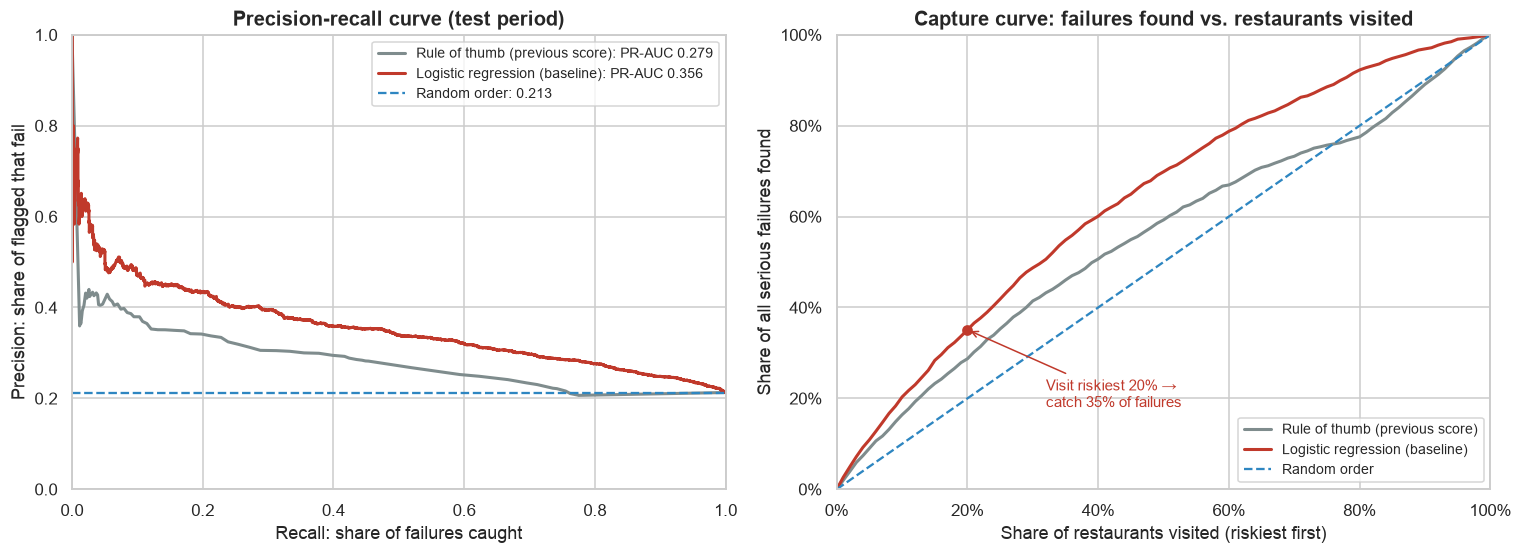

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5.2))

# Left: precision-recall curves
for name, scores, color in [("Rule of thumb (previous score)", rule_scores, GRAY),
                            ("Logistic regression (baseline)", baseline_scores, FAIL_COLOR)]:
    precision, recall, _ = precision_recall_curve(y_test, scores)
    axes[0].plot(recall, precision, color=color, lw=2,
                 label=f"{name}: PR-AUC {average_precision_score(y_test, scores):.3f}")
axes[0].axhline(y_test.mean(), color=PASS_COLOR, ls="--", lw=1.5, label=f"Random order: {y_test.mean():.3f}")
axes[0].set(title="Precision-recall curve (test period)", xlabel="Recall: share of failures caught",
            ylabel="Precision: share of flagged that fail", xlim=(0, 1), ylim=(0, 1))
axes[0].legend(loc="upper right", fontsize=9)

# Right: capture curve, i.e., the inspector's view of the ranked list
shares = np.linspace(0, 1, 101)
for name, scores, color in [("Rule of thumb (previous score)", rule_scores, GRAY),
                            ("Logistic regression (baseline)", baseline_scores, FAIL_COLOR)]:
    axes[1].plot(shares, [capture_rate(y_test, scores, s) if s > 0 else 0 for s in shares], color=color, lw=2, label=name)
axes[1].plot([0, 1], [0, 1], color=PASS_COLOR, ls="--", lw=1.5, label="Random order")
top20 = capture_rate(y_test, baseline_scores, 0.20)
axes[1].scatter([0.2], [top20], color=FAIL_COLOR, zorder=5)
axes[1].annotate(f"Visit riskiest 20% →\ncatch {top20:.0%} of failures", (0.2, top20), xytext=(0.32, top20 - 0.17),
                 arrowprops={"arrowstyle": "->", "color": FAIL_COLOR}, fontsize=10, color=FAIL_COLOR)
axes[1].set(title="Capture curve: failures found vs. restaurants visited", xlabel="Share of restaurants visited (riskiest first)",
            ylabel="Share of all serious failures found", xlim=(0, 1), ylim=(0, 1))
axes[1].xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
axes[1].yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
axes[1].legend(loc="lower right", fontsize=9)
plt.tight_layout()
save_fig(fig, "baseline_evaluation")
plt.show()

### Confusion matrix at the default threshold

The model outputs a risk probability. At the default cut-off of 0.5 (with balanced class weights), inspections above the line are flagged.

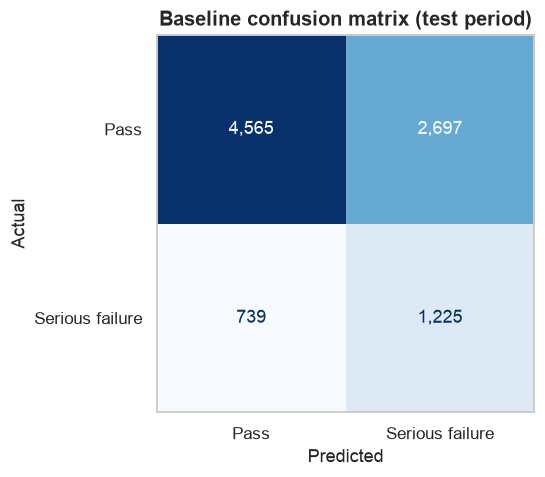

                 precision    recall  f1-score   support

           Pass      0.861     0.629     0.727      7262
Serious failure      0.312     0.624     0.416      1964

       accuracy                          0.628      9226
      macro avg      0.587     0.626     0.571      9226
   weighted avg      0.744     0.628     0.661      9226



In [10]:
fig, ax = plt.subplots(figsize=(5.5, 4.5))
ConfusionMatrixDisplay.from_predictions(y_test, baseline_pred, display_labels=["Pass", "Serious failure"],
                                        cmap="Blues", values_format=",", ax=ax, colorbar=False)
ax.set(title="Baseline confusion matrix (test period)", xlabel="Predicted", ylabel="Actual")
ax.grid(False)
plt.tight_layout()
plt.show()

print(classification_report(y_test, baseline_pred, target_names=["Pass", "Serious failure"], digits=3))

## 9. What drives the predictions?

Each coefficient is converted to an **odds ratio**: the multiplier on the odds of a serious failure when a numeric feature rises by one standard deviation, or when a category applies (compared with the other categories of the same feature; every category is kept, so effects are relative to the average). Values above 1 raise the risk, below 1 lower it.

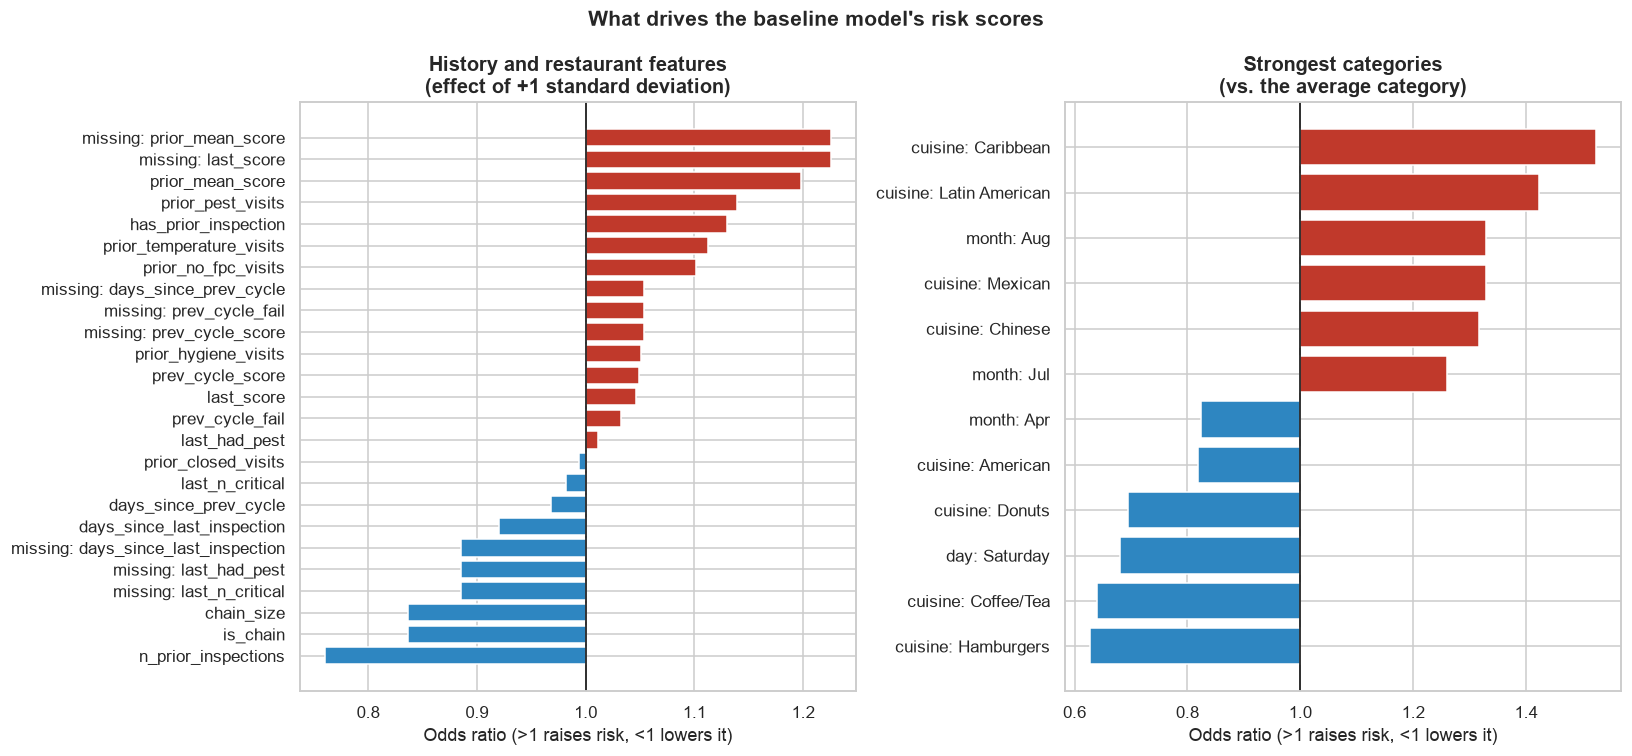

In [11]:
feature_names = baseline.named_steps["prep"].get_feature_names_out()
odds = pd.Series(np.exp(baseline.named_steps["model"].coef_[0]), index=feature_names)
odds.index = (odds.index.str.replace("num__", "").str.replace("cat__", "").str.replace("missingindicator_", "missing: ")
              .str.replace("cuisine_group_", "cuisine: ").str.replace("boro_", "borough: ")
              .str.replace("inspection_dow_", "day: ").str.replace("inspection_month_", "month: "))
month_names = {f"month: {m}": f"month: {name}" for m, name in
               zip(range(1, 13), ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"])}
odds = odds.rename(index=month_names)
is_category = odds.index.str.contains(": ") & ~odds.index.str.startswith("missing")
numeric_odds = odds[~is_category].sort_values()
category_odds = pd.concat([odds[is_category].nlargest(6), odds[is_category].nsmallest(6)]).sort_values()

fig, axes = plt.subplots(1, 2, figsize=(15, 7))
for ax, values, title in [(axes[0], numeric_odds, "History and restaurant features\n(effect of +1 standard deviation)"),
                          (axes[1], category_odds, "Strongest categories\n(vs. the average category)")]:
    ax.barh(values.index, values.values - 1, left=1, color=[FAIL_COLOR if v > 1 else PASS_COLOR for v in values.values])
    ax.axvline(1, color="black", lw=1)
    ax.set(title=title, xlabel="Odds ratio (>1 raises risk, <1 lowers it)")
fig.suptitle("What drives the baseline model's risk scores", fontweight="bold", fontsize=14)
plt.tight_layout()
save_fig(fig, "baseline_odds_ratios")
plt.show()

**Reading the chart:**
* **A bad track record raises the risk:** a higher average earlier score, more earlier visits with pests, temperature problems or no certified food manager.
* **Summer is riskier:** inspections in July and August carry about 25–35% higher odds than an average month, consistent with heat making it harder to keep food at safe temperatures.
* **Cuisine and chain status matter:** Caribbean and Latin American restaurants carry the highest odds, while hamburger, coffee/tea and donut shops and larger chains carry the lowest, matching the EDA.
* **More clean inspections lower the risk:** once past problems are accounted for, a longer inspection record (with no problems) points to a steadier operation.

**Caution:** several features overlap heavily (the three score-history features; the "missing" flags, which all switch on together for brand-new restaurants). In that situation the weight is split among related features, so individual coefficients should be read as *directions*, not exact effects. Regularized and tree-based models in Module 24 will handle this better.

## 10. Results in plain language

In [12]:
test_rate = y_test.mean()
for share in (0.10, 0.20, 0.30):
    caught = capture_rate(y_test, baseline_scores, share)
    hit_rate = caught * y_test.sum() / round(len(y_test) * share)
    print(f"Visit the riskiest {share:.0%} first -> find {caught:.0%} of all serious failures; "
          f"{hit_rate:.0%} of those visits find a failure (vs {test_rate:.0%} at random)")

Visit the riskiest 10% first -> find 20% of all serious failures; 43% of those visits find a failure (vs 21% at random)
Visit the riskiest 20% first -> find 35% of all serious failures; 37% of those visits find a failure (vs 21% at random)
Visit the riskiest 30% first -> find 49% of all serious failures; 35% of those visits find a failure (vs 21% at random)


**Interpreting the metric.** The baseline's **PR-AUC is 0.356** on the most recent six months of inspections, against **0.213** for a random order and **0.279** for the rule of thumb of ranking by previous score. In plain terms:

* If inspectors visit the **riskiest 20%** of restaurants first, they find **35% of all serious failures**, and **37% of those visits** uncover a serious failure, compared with **21%** when visiting in random order. That is **about 1.7 times the hit rate**.
* Using the riskiest 10%, the hit rate is **43%, about twice the random rate**.
* Cross-validation on the training period gives a PR-AUC of **0.297 ± 0.046**, so the model's advantage is consistent over time and not a lucky split. The test score is a little higher partly because failures were more common in the test period.

At the default cut-off the model catches **62% of serious failures** (recall) but only **31% of flagged inspections** actually fail (precision). In practice the city would pick the cut-off to match inspector capacity, which is why the ranked-list view matters more than a single threshold.

**Conclusion.** Inspection history, cuisine, chain status and season contain a real, repeatable signal. A simple, explainable model already beats the "re-inspect whoever scored badly last time" rule, but it is far from perfect: inspection outcomes are partly unpredictable.

**Next steps for Module 24:**
1. Compare more models: k-nearest neighbors, decision tree, random forest and gradient boosting, tuned with **GridSearchCV** using time-ordered cross-validation.
2. Tune the decision cut-off for a realistic inspector capacity, and compare models on capture rate at that capacity.
3. Add features: neighborhood-level failure history, recent 311 rodent and food complaints near the restaurant, and violation trends (getting better or worse).
4. Handle overlapping features (regularization strength, feature selection) and explain the final model with permutation importance.